In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv('SouthGermanCredit.asc', sep=r'\s+')

In [4]:
# Стандартизація та підготовка
X = df.drop(columns=['kredit']) if 'kredit' in df.columns else df
X_scaled = StandardScaler().fit_transform(X)

In [5]:
# Діапазон кількості кластерів
k_range = range(2, 11)

km_sil, km_db = [], []
agg_sil, agg_db = [], []

for k in k_range:
    # K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_scaled)
    km_sil.append(silhouette_score(X_scaled, km_labels))
    km_db.append(davies_bouldin_score(X_scaled, km_labels))

    # Agglomerative Clustering
    agg = AgglomerativeClustering(n_clusters=k)
    agg_labels = agg.fit_predict(X_scaled)
    agg_sil.append(silhouette_score(X_scaled, agg_labels))
    agg_db.append(davies_bouldin_score(X_scaled, agg_labels))

print(k_range[np.argmax(km_sil)])
print(k_range[np.argmin(km_db)])

3
10


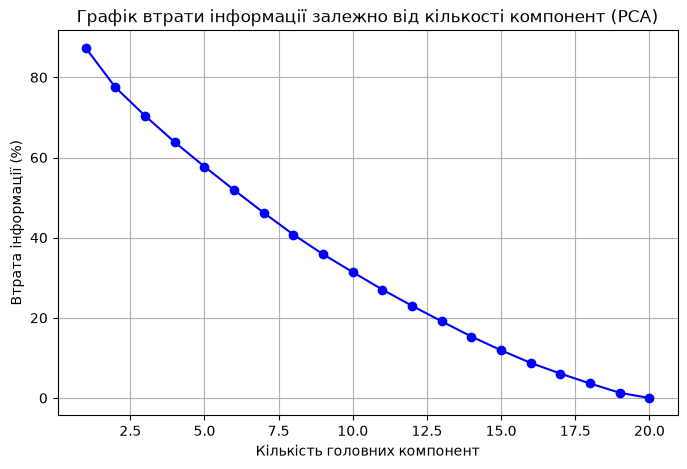

In [6]:
#Графік втрати інформації при зменшенні розмірності.
pca_full = PCA().fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
information_loss = (1 - cumulative_variance) * 100

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(information_loss) + 1), information_loss, marker='o', color='b')
plt.title("Графік втрати інформації залежно від кількості компонент (PCA)")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Втрата інформації (%)")
plt.grid(True)
plt.show()

In [7]:
# Трансформація даних зі збереженням 70% інформації
n_components_70 = np.argmax(cumulative_variance >= 0.70) + 1
pca_reduced = PCA(n_components=n_components_70)
X_reduced = pca_reduced.fit_transform(X_scaled)


In [8]:
# Повторний підбір оптимальної кількості кластерів на перетвореному датасеті
best_k_reduced = 3
optimal_model = KMeans(n_clusters=best_k_reduced, random_state=42, n_init=10)
clusters_reduced = optimal_model.fit_predict(X_reduced)

In [9]:
# Кластеризація на повному датасеті з оптимальним k
optimal_model_full = KMeans(n_clusters=best_k_reduced, random_state=42, n_init=10)
clusters_full = optimal_model_full.fit_predict(X_scaled)

In [10]:
# Порівняння розбиттів на кластери для повного датасету і після втраті 30% інформації.
from sklearn.metrics import adjusted_rand_score
ari_score = adjusted_rand_score(clusters_full, clusters_reduced)

print(f"ARI між повним і зменшеним датасетом: {ari_score:.4f}")

Adjusted Rand Index (ARI) між повним і зменшеним датасетом: 0.3594


In [ ]:
# За допомогою PCA було встановлено, що для утримання втрат інформації в межах до 30% необхідно залишити 11 головних компонент.
# Отримане значення ARI на рівні 0.3594 вказує на помірну схожість кластерних структур. Це означає, що після скорочення розмірності датасету деталізований поділ дещо змінився, проте загальні закономірності розподілу даних збереглися.